<a href="https://colab.research.google.com/github/caiohc28/Tech_Challenge/blob/main/Comportamento_e_Pagamentos_Olist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Comportamento e Pagamentos | Olist

Objetivo: analisar o comportamento de compra do cliente

Perguntas que este notebook responde:

1 . Quais os meios de pagamentos mais utilizados?

2 . Qual a correlação entre o valor gasto e o número de parcelas

3 . Qual a recencia, frequencia e monetização por cliente único

4 . Qual a taxa de retenção e recompra por coorte (mês em que o cliente realizou a primeira compra)


Base de análise: pedidos entregues, com datas de aprovação e de entrega preenchidas.
Fonte: Brazilian E-Commerce Public Dataset by Olist (Kaggle).

## 1. Importação das bibliotecas


In [2]:
# manipuluação dos dados
import pandas as pd
import numpy as np

# visualização dos dados
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

## 2. Carregamento dos dados

In [3]:
df_olist = pd.read_csv('olist_customers_dataset.csv')

## 3. Criação dataset ordens e pagamentos


In [4]:
df_orders = pd.read_csv('olist_orders_dataset.csv')
df_payments = pd.read_csv('olist_order_payments_dataset.csv')

# Traduzindo as formas de pagamento para o português
mapa_pagamentos = {
    'credit_card': 'Cartão de Crédito',
    'boleto': 'Boleto',
    'voucher': 'Voucher',
    'debit_card': 'Cartão de Débito',
    'not_defined': 'Não Definido'
}
df_payments['payment_type'] = df_payments['payment_type'].map(mapa_pagamentos).fillna(df_payments['payment_type'])

## 1. Quais os Meios de Pagamento Mais Utilizados?

In [9]:
# Estatísticas descritivas
estatisticas_pagamento = df_payments.groupby('payment_type')[['payment_value']].describe()
display(estatisticas_pagamento)

payment_value                                          \
                          count        mean         std    min      25%   
payment_type                                                              
Boleto                  19784.0  145.034435  213.581061  11.62  55.5225   
Cartão de Crédito       76795.0  163.319021  222.119311   0.01  62.2100   
Cartão de Débito         1529.0  142.570170  245.793401  13.38  51.1000   
Não Definido                3.0    0.000000    0.000000   0.00   0.0000   
Voucher                  5775.0   65.703354  115.519185   0.00  18.0350   

                                               
                      50%       75%       max  
payment_type                                   
Boleto              93.89  160.7625   7274.88  
Cartão de Crédito  106.87  181.2100  13664.08  
Cartão de Débito    89.30  154.3200   4445.50  
Não Definido         0.00    0.0000      0.00  
Voucher             39.28   80.0000   3184.34

Quantidade de Transações (count): O cartão de crédito é o método mais utilizado, com mais de 76 mil transações. O boleto vem em segundo lugar, com cerca de 19,7 mil transações. Voucher e cartão de débito (debit_card) aparecem na sequência.

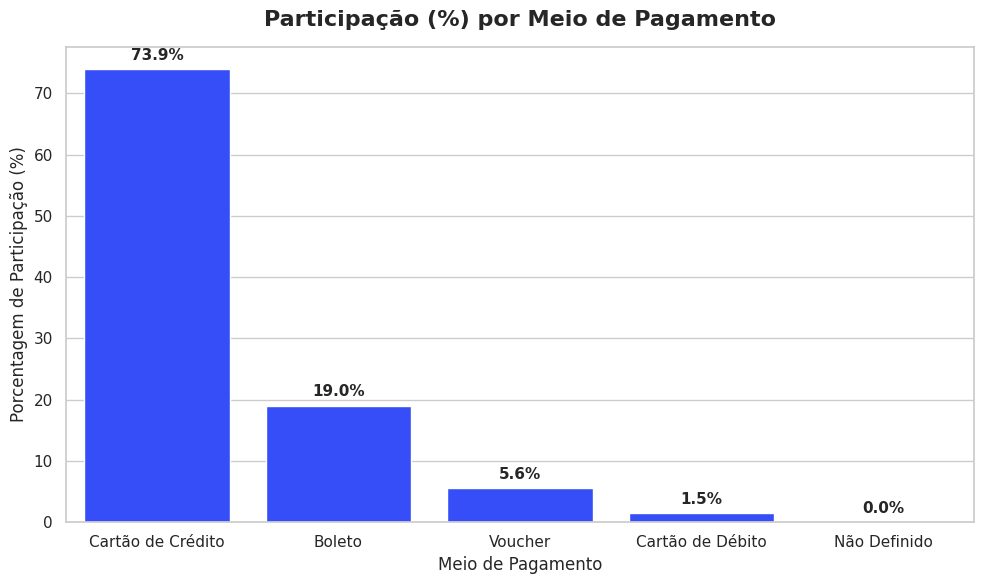

In [6]:
# Grafico de barras em porcentagem

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))
payment_percentage = (df_payments['payment_type'].value_counts(normalize=True) * 100)
sns.barplot(
    x=payment_percentage.index,
    y=payment_percentage.values,
    ax=ax,
    palette=['#364ef7']*len(payment_percentage),
    hue=payment_percentage.index,
    legend=False,
    saturation=1
)
ax.set_title('Participação (%) por Meio de Pagamento', fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Meio de Pagamento', fontsize=12)
ax.set_ylabel('Porcentagem de Participação (%)', fontsize=12)
for i, v in enumerate(payment_percentage.values):
    ax.text(i, v + 1, f'{v:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

A distribuição de meios de pagamento comporta-se com dominância expressiva do Cartão de Crédito (73.92%), seguido pelo Boleto (19.04%), Voucher (5.56%) e Cartão de Débito (1.47%).

## Análise do valor gasto e o número de parcelas



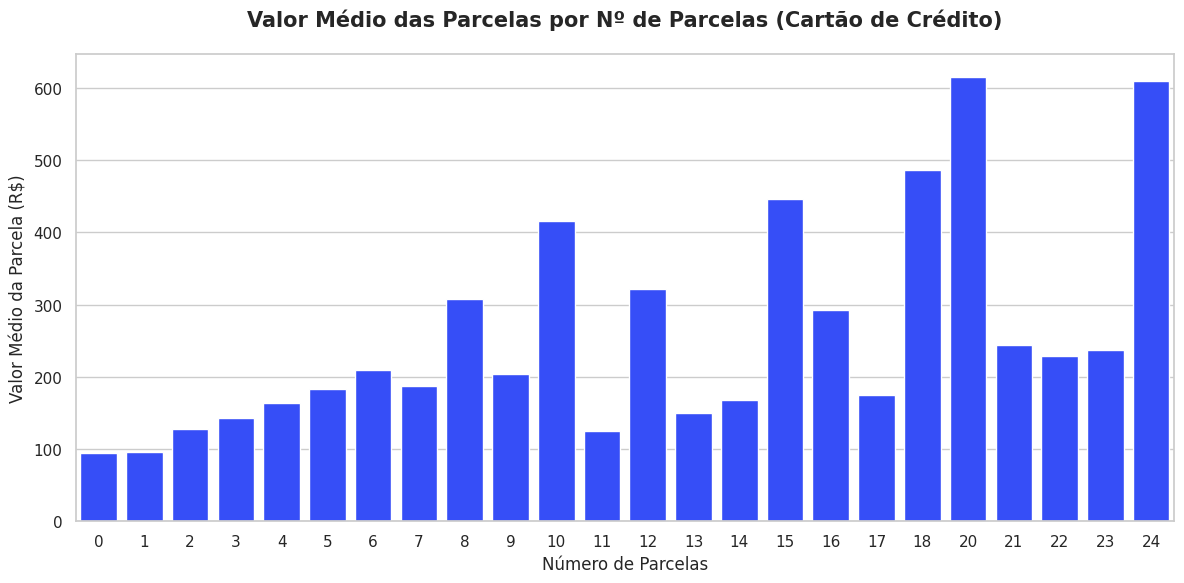

In [10]:
# Agrupamento do valor médio por parcelas

df_credit = df_payments[df_payments['payment_type'] == 'Cartão de Crédito']
installments_value = df_credit.groupby('payment_installments')['payment_value'].mean().reset_index()

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(
    data=installments_value,
    x='payment_installments',
    y='payment_value',
    ax=ax,
    color='#364ef7',
    saturation=1
)

ax.set_title('Valor Médio das Parcelas por Nº de Parcelas (Cartão de Crédito)', fontsize=15, fontweight='bold', pad=20)
ax.set_xlabel('Número de Parcelas', fontsize=12)
ax.set_ylabel('Valor Médio da Parcela (R$)', fontsize=12)

plt.tight_layout()
plt.show()

O Ticket Médio por Número de Parcelas flutua à medida que o número de parcelas aumenta, evidenciando picos característicos de compras de alto valor parceladas em 10, 15, 20 ou 24 vezes no cartão de crédito.

## 2. Qual a correlação entre o valor gasto e o número de parcelas?


In [11]:
# Correlação de Pearson
corr_pearson = df_payments['payment_value'].corr(df_payments['payment_installments'], method='pearson')
print(f"Coeficiente de Correlação de Pearson: {corr_pearson:.4f}")


Coeficiente de Correlação de Pearson: 0.3308


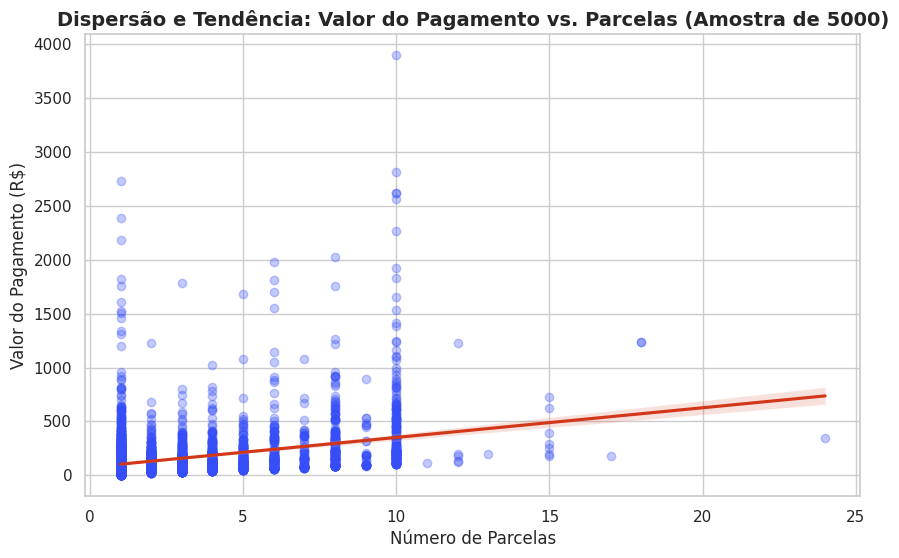

In [12]:
# Gráfico de dispersão com uma amostra de 5000
df_sample = df_payments.sample(n=5000, random_state=42) if len(df_payments) > 5000 else df_payments

plt.figure(figsize=(10, 6))
sns.regplot(data=df_sample, x='payment_installments', y='payment_value',
            scatter_kws={'alpha':0.3, 'color': '#364ef7'}, line_kws={'color': '#d23718'})
saturation=1
plt.title('Dispersão e Tendência: Valor do Pagamento vs. Parcelas (Amostra de 5000)', fontsize=14, fontweight='bold')
plt.xlabel('Número de Parcelas', fontsize=12)
plt.ylabel('Valor do Pagamento (R$)', fontsize=12)
plt.show()

Foi calculado o coeficiente de correlação de Pearson, que apresentou valor de 0,33, indicando uma correlação positiva moderada entre o valor da compra e a quantidade de parcelas escolhidas pelos clientes. Observa-se que compras de maior valor, especialmente acima de R$ 1.000, tendem a se concentrar em quantidades mais elevadas de parcelas, como 10 vezes. Por outro lado, compras de menor valor estão distribuídas por praticamente todas as opções de parcelamento. Dessa forma, os resultados sugerem que, à medida que o valor da compra aumenta, também cresce a tendência dos clientes optarem pelo parcelamento, caracterizando uma relação positiva entre essas variáveis.




## 3. Qual a Recência, frequência, monetização (RFM) por customer unique





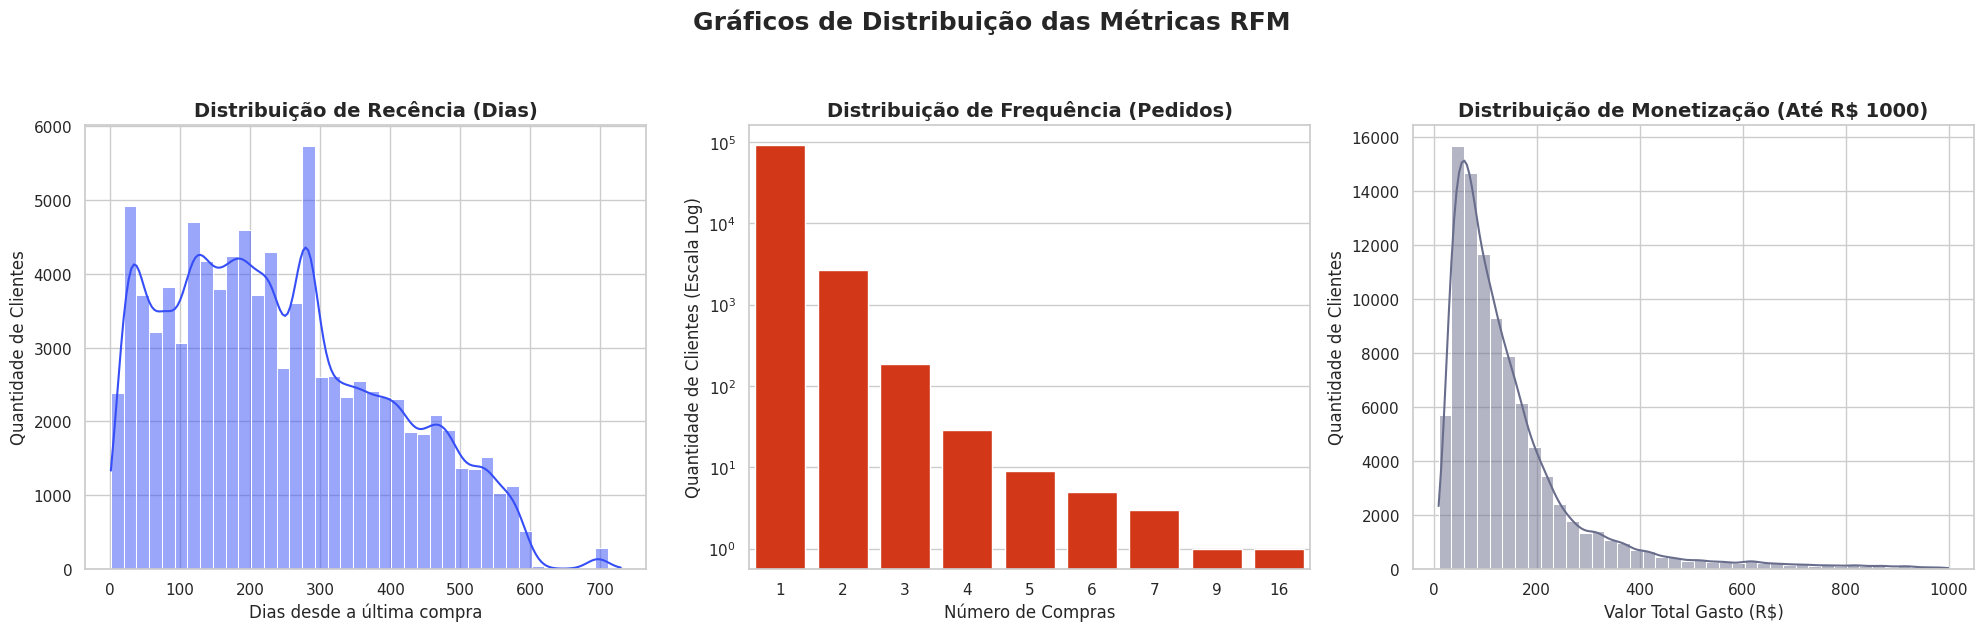

In [13]:
df_rfm_raw = df_orders.merge(df_olist, on='customer_id', how='inner')
df_rfm_raw = df_rfm_raw.merge(df_payments, on='order_id', how='inner')
df_rfm_raw['order_purchase_timestamp'] = pd.to_datetime(df_rfm_raw['order_purchase_timestamp'])
df_rfm_raw = df_rfm_raw[df_rfm_raw['order_status'].isin(['delivered', 'shipped', 'invoiced'])]
data_referencia = df_rfm_raw['order_purchase_timestamp'].max() + pd.Timedelta(days=1)


df_rfm = df_rfm_raw.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (data_referencia - x.max()).days,
    'order_id': 'nunique',
    'payment_value': 'sum'
}).reset_index()

df_rfm.columns = ['customer_unique_id', 'Recencia', 'Frequencia', 'Monetizacao']
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Recência
sns.histplot(df_rfm['Recencia'], bins=40, kde=True, ax=axes[0], color='#364ef7')
axes[0].set_title('Distribuição de Recência (Dias)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Dias desde a última compra')
axes[0].set_ylabel('Quantidade de Clientes')

# 2.Frequência
num_categorias = len(df_rfm['Frequencia'].unique())
sns.countplot(data=df_rfm, x='Frequencia', ax=axes[1], palette=['#d23718'] * num_categorias, hue='Frequencia', legend=False, saturation=1)
axes[1].set_title('Distribuição de Frequência (Pedidos)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Número de Compras')
axes[1].set_ylabel('Quantidade de Clientes (Escala Log)')
axes[1].set_yscale('log')

# 3. Monetização
monetizacao_filtrada = df_rfm[df_rfm['Monetizacao'] <= 1000]
sns.histplot(monetizacao_filtrada['Monetizacao'], bins=40, kde=True, ax=axes[2], color='#696d8c')
axes[2].set_title('Distribuição de Monetização (Até R$ 1000)', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Valor Total Gasto (R$)')
axes[2].set_ylabel('Quantidade de Clientes')

plt.suptitle('Gráficos de Distribuição das Métricas RFM', fontsize=18, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

Recência (dias desde a última compra): os clientes estão amplamente distribuídos em uma faixa que vai de 0 a mais de 700 dias. É possível observar picos expressivos de atividade ao redor de 80 a 100 dias e um pico ainda maior próximo dos 320 dias. Isso sinaliza campanhas ou períodos sazonais de grande volume de vendas . Como a barra mais alta se concentra próxima aos 320 dias, uma parte muito significativa da base de clientes não realiza compras há quase um ano, exigindo estratégias de engajamento.

Frequência (quantidade de pedidos): devido à escala logarítmica necessária para visualização, fica claro que a maioria dos clientes (mais de 90.000) possui frequência igual a 1, ou seja há uma alta concentração de compra única. O número de clientes que efetuam 2 ou mais compras cai drasticamente (menos de 3.000 clientes realizaram 2 compras). Clientes com frequências atípicas (como 5, 9 ou até 17 compras) são raríssimas exceções (outliers).

Monetização (valor Total Gasto até 1000 reais): uma grande massa de transações ocorre em valores baixos (cauda longa). O pico de frequência de clientes está concentrado entre 40,00 e 150,00 reais. À medida que o valor total gasto se aproxima de 400,00 reais, a quantidade de clientes cai de forma muito acentuada, tornando o grupo de clientes que gastam acima de R$ 600,00 bastante seleto e de altíssimo valor (VIPs) para focar em estratégias de relacionamento.

## 4. Qual a taxa de retenção e recompra por coorte (mês em que o cliente realizou a primeira compra)


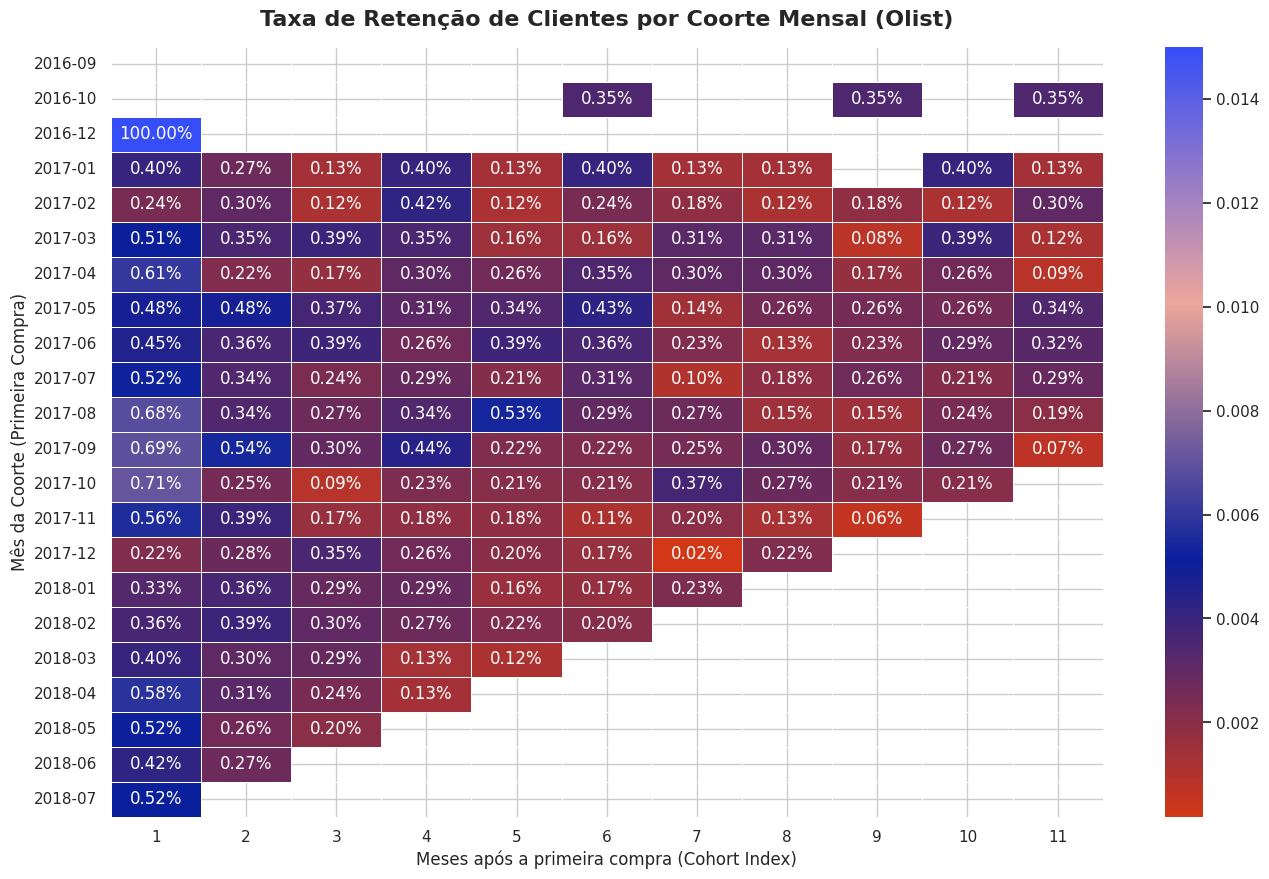

In [21]:
from matplotlib.colors import LinearSegmentedColormap

df_cohort = df_orders.merge(df_olist, on='customer_id', how='inner')
df_cohort['order_purchase_timestamp'] = pd.to_datetime(df_cohort['order_purchase_timestamp'])
df_cohort = df_cohort[df_cohort['order_status'].isin(['delivered', 'shipped', 'invoiced'])]

df_cohort['order_month'] = df_cohort['order_purchase_timestamp'].dt.to_period('M')
df_cohort['cohort_month'] = df_cohort.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min').dt.to_period('M')

def calculate_cohort_index(df):
    years_diff = df['order_month'].dt.year - df['cohort_month'].dt.year
    months_diff = df['order_month'].dt.month - df['cohort_month'].dt.month
    return years_diff * 12 + months_diff

df_cohort['cohort_index'] = calculate_cohort_index(df_cohort)
cohort_group = df_cohort.groupby(['cohort_month', 'cohort_index'])['customer_unique_id'].nunique().reset_index()
cohort_matrix = cohort_group.pivot(index='cohort_month', columns='cohort_index', values='customer_unique_id')

cohort_sizes = cohort_matrix.iloc[:, 0]
retention_matrix = cohort_matrix.divide(cohort_sizes, axis=0)

custom_colors = ["#d23718", "#0a1f9c", "#eda69b", "#364ef7"]
cmap_custom = LinearSegmentedColormap.from_list("custom_retention", custom_colors, N=256)

plt.figure(figsize=(16, 10))
sns.heatmap(
    retention_matrix.iloc[:-1, 1:12],
    annot=True,
    fmt='.2%',
    cmap=cmap_custom,
    linewidths=.5,
    vmax=0.015
)
plt.title('Taxa de Retenção de Clientes por Coorte Mensal (Olist)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Meses após a primeira compra (Cohort Index)', fontsize=12)
plt.ylabel('Mês da Coorte (Primeira Compra)', fontsize=12)
plt.show()

In [17]:
df_cohort = df_orders.merge(df_olist, on='customer_id', how='inner')
df_cohort['order_purchase_timestamp'] = pd.to_datetime(df_cohort['order_purchase_timestamp'])
df_cohort = df_cohort[df_cohort['order_status'].isin(['delivered', 'shipped', 'invoiced'])]

# recompra na base histórica
total_clientes_coorte = df_cohort['customer_unique_id'].nunique()
clientes_com_recompra = df_cohort.groupby('customer_unique_id')['order_id'].nunique()
clientes_recorrentes = (clientes_com_recompra > 1).sum()
clientes_compra_unica = total_clientes_coorte - clientes_recorrentes

print(f"Total de clientes analisados na coorte: {total_clientes_coorte:,}")
print(f"Clientes com compra única: {clientes_compra_unica:,} ({ (clientes_compra_unica/total_clientes_coorte)*100:.2f}%)")
print(f"Clientes recorrentes (recompra): {clientes_recorrentes:,} ({ (clientes_recorrentes/total_clientes_coorte)*100:.2f}%)")

Total de clientes analisados na coorte: 94,697
Clientes com compra única: 91,821 (96.96%)
Clientes recorrentes (recompra): 2,876 (3.04%)


Há baixa recorrência de compras, pois cerca de 97% dos consumidores realizam apenas uma compra na plataforma e apenas 3% são recorrentes. A retenção de clientes no mês 1 (o mês imediatamente posterior à primeira compra) e nos meses seguintes fica quase sempre abaixo de 1% (variando geralmente entre 0.10% e 0.70%)
Esse comportamento indica um modelo transacional de altíssima dependência de novos clientes (cauda longa), onde a fidelização ativa é baixa e a grande maioria dos usuários realiza apenas uma compra pontual e não retorna de maneira orgânica.

